# 02 Synthetic students

The catalog has no students, so I simulate them: 2,000 students with a learning history and 200 new students with none (100 for tuning, 100 for testing). The columns are what a learning platform would normally log. Seed 42, no API key needed.

In [1]:
# Step 0: setup (works in Colab and on a laptop)
import os, sys
from pathlib import Path

# Colab: where the project folder sits in Google Drive
DRIVE_PROJECT = "/content/drive/MyDrive/LearnPath"

if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = Path(DRIVE_PROJECT)
else:
    PROJECT_DIR = Path.cwd().parent   # running from the notebooks/ folder

assert (PROJECT_DIR / "src" / "learnpath").exists(), f"Project folder not found: {PROJECT_DIR}"
os.environ["LEARNPATH_DIR"] = str(PROJECT_DIR)
sys.path.insert(0, str(PROJECT_DIR / "src"))
print("Project folder:", PROJECT_DIR)

Mounted at /content/drive
Project folder: /content/drive/MyDrive/LearnPath


In [2]:
# Step 1: load the clean catalog
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from learnpath import catalog, config, plots, synth

plots.apply_style()
courses = catalog.load_courses()
print(len(courses), "courses")

3422 courses


Assumptions A1 to A8:

1. Each student cares about one or two topics, and about 80% of their courses come from them.
2. Students move up over time. Course level follows their current level and goes up after finished courses.
3. Popularity has a long tail.
4. Some courses are taken in sequence: 3 popular paths per larger topic, followed by 40% of students.
5. Finishing is less likely above the student's real level, with little weekly time, or in a format they don't like.
6. Guided projects (1 to 2 hours) get finished more often.
7. For 25% of students, one stated interest isn't what they actually take.
8. Self-reported level is right 70% of the time, otherwise off by one.

Learning style is only a format preference here, not a claim that people learn better in their "style". Age, education and region are only used for the fairness check. `true_interests` and `true_level` drive the simulation, and no model ever sees them.

In [3]:
# Step 2: generate
students, inter, cold, cold_truth, world, tracks = synth.generate(courses)
print("Students:", len(students))
print("Interactions:", len(inter))
print("New students (no history):", len(cold), cold["split"].value_counts().to_dict())
print("Popular course paths:", sum(len(v) for v in tracks.values()))

Students: 2000
Interactions: 18219
New students (no history): 200 {'val': 100, 'test': 100}
Popular course paths: 126


In [4]:
students.drop(columns=["true_interests", "true_level"]).head()

,student_id,age_band,education_level,region,learning_style,weekly_hours,goal,self_reported_level,stated_interests
0,S0001,25-34,Bachelor's,Sub-Saharan Africa,reading,4.0,career switch,Beginner,leadership and management; environmental scien...
1,S0002,18-24,High school,Sub-Saharan Africa,hands_on,4.0,career switch,Beginner,finance; other languages
2,S0003,18-24,Master's or higher,Middle East & North Africa,reading,4.0,career switch,Advanced,finance
3,S0004,18-24,Bachelor's,South Asia,visual,3.5,career switch,Intermediate,personal development
4,S0005,18-24,Bachelor's,South Asia,visual,4.0,upskill for current job,Beginner,business essentials; finance


In [5]:
inter.head()

,student_id,course_id,enrolled_at,time_spent_hours,progress,completed,rating,split
0,S0001,C2507,2025-02-03,9.0,0.27,0,NaN,train
1,S0001,C1671,2025-02-08,11.7,1.00,1,NaN,train
2,S0001,C0315,2025-02-27,10.6,1.00,1,NaN,train
3,S0001,C0848,2025-03-20,14.9,1.00,1,NaN,train
4,S0001,C1459,2025-04-24,16.2,1.00,1,5.0,train


Split: for each student the last 2 courses are the test set, the one before is validation, and the rest is training. The split follows time, so no model sees the future.

In [6]:
# Step 3: check the split
print(inter["split"].value_counts().to_dict())
print("Courses per student:", inter.groupby("student_id").size().describe().round(1).to_dict())

{'train': 12219, 'test': 4000, 'val': 2000}
Courses per student: {'count': 2000.0, 'mean': 9.1, 'std': 2.2, 'min': 4.0, '25%': 8.0, '50%': 9.0, '75%': 10.0, 'max': 15.0}


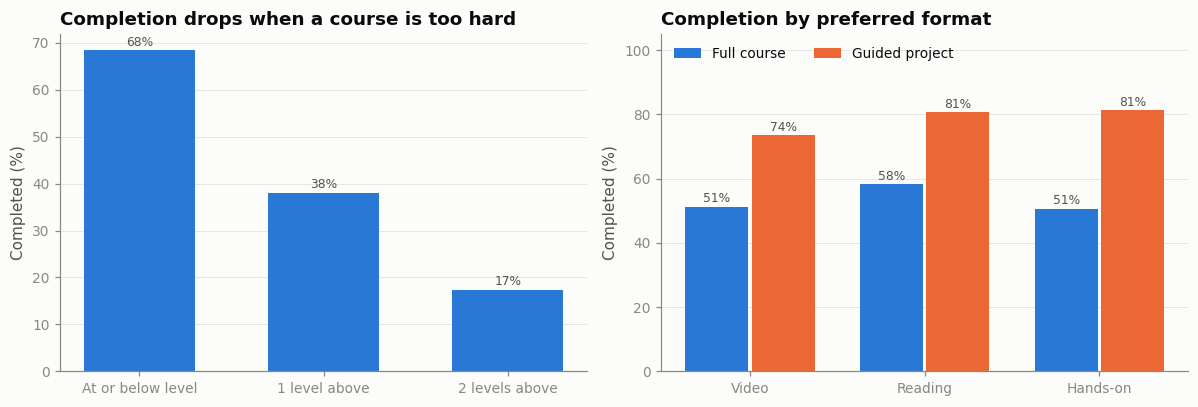

In [7]:
# Step 4: do the rules actually show up in the data?
m = inter.merge(courses[["course_id", "level_num", "format", "subdomain"]], on="course_id") \
         .merge(students[["student_id", "true_level", "learning_style", "true_interests"]], on="student_id")
m["levels_above"] = (m["level_num"] - m["true_level"]).clip(lower=0)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
g = m.groupby("levels_above")["completed"].mean()
bars = axes[0].bar(["At or below level", "1 level above", "2 levels above"], g.values * 100,
                   color=plots.PALETTE[0], width=0.6)
plots.label_bars(axes[0], bars, fmt="{:.0f}%")
axes[0].set_title("Completion drops when a course is too hard")
axes[0].set_ylabel("Completed (%)")

t = m.groupby(["learning_style", "format"])["completed"].mean().unstack() * 100
t = t.reindex(["visual", "reading", "hands_on"])
x = np.arange(len(t))
w = 0.36
b1 = axes[1].bar(x - w / 2 - 0.01, t["course"], w, color=plots.PALETTE[0], label="Full course")
b2 = axes[1].bar(x + w / 2 + 0.01, t["guided_project"], w, color=plots.PALETTE[1], label="Guided project")
plots.label_bars(axes[1], b1, fmt="{:.0f}%")
plots.label_bars(axes[1], b2, fmt="{:.0f}%")
axes[1].set_xticks(x, ["Video", "Reading", "Hands-on"])
axes[1].set_title("Completion by preferred format")
axes[1].set_ylabel("Completed (%)")
axes[1].legend(loc="upper left", ncol=2)
axes[1].set_ylim(0, 105)
fig.tight_layout()
plots.save(fig, "02_completion_checks")
plt.show()

In [8]:
on_interest = m.apply(lambda r: r["subdomain"] in r["true_interests"].split("; "), axis=1).mean()
print(f"Courses inside the student's own interests: {on_interest:.0%} (A1 says about 80%)")
print(f"Overall completion rate: {inter['completed'].mean():.0%}")

Courses inside the student's own interests: 84% (A1 says about 80%)
Overall completion rate: 56%


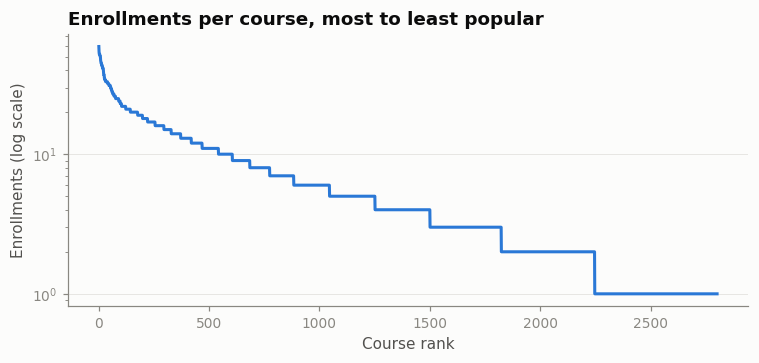

Courses with no enrollments at all: 621 of 3422 (18%)
Top 10% of courses get 37% of enrollments


In [9]:
# Step 5: popularity long tail
counts = inter["course_id"].value_counts()
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(np.arange(1, len(counts) + 1), counts.values, color=plots.PALETTE[0], linewidth=2)
ax.set_yscale("log")
ax.set_title("Enrollments per course, most to least popular")
ax.set_xlabel("Course rank")
ax.set_ylabel("Enrollments (log scale)")
fig.tight_layout()
plots.save(fig, "02_popularity_tail")
plt.show()
never = len(courses) - counts.size
print(f"Courses with no enrollments at all: {never} of {len(courses)} ({never/len(courses):.0%})")
print(f"Top 10% of courses get {counts.head(len(counts)//10).sum()/counts.sum():.0%} of enrollments")

Courses nobody has taken can't come out of CF, only out of the content side. That's one reason for the hybrid.

One thing to keep in mind: students here pick by topic, and their stated interests are the topic names, which also appear in every course document. That helps TF-IDF more than embeddings, so TF-IDF winning later says more about this data than about the models.

In [10]:
# Step 6: save
config.ensure_dirs()
students.to_csv(config.STUDENTS, index=False)
inter.to_csv(config.INTERACTIONS, index=False)
cold.to_csv(config.COLD_START, index=False)
cold_truth.to_csv(config.COLD_START_TRUTH, index=False)
print("Saved to", config.DATA_SYNTHETIC)

Saved to /content/drive/MyDrive/LearnPath/data/synthetic
